In [6]:
from pathlib import Path
import random
import yaml
import matplotlib.pyplot as plt
from PIL import Image

In [18]:
# Chemin du dataset
DATASET_DIR = Path("../trafic_data")

# Vérification
print("Dataset accessible :", DATASET_DIR.exists())
print("Chemin du dataset :", DATASET_DIR.resolve())

Dataset accessible : True
Chemin du dataset : C:\Users\Youcode\Desktop\TrafficSight\RoadVision_AI\trafic_data


In [19]:
# Afficher les dossiers et fichiers à la racine du dataset

for element in sorted(DATASET_DIR.iterdir()):
    print(element.name, ":", "Dossier" if element.is_dir() else "Fichier")

data_1.yaml : Fichier
train : Dossier
valid : Dossier


In [20]:
# Extensions d'images acceptées
EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

for split in ["train", "valid"]:
    dossier_images = DATASET_DIR / split / "images"
    dossier_labels = DATASET_DIR / split / "labels"

    images = [
        f for f in dossier_images.iterdir()
        if f.is_file() and f.suffix.lower() in EXTENSIONS
    ]

    labels = list(dossier_labels.glob("*.txt"))

    print(f"\n--- {split.upper()} ---")
    print("Nombre d'images :", len(images))
    print("Nombre de Labels :", len(labels))


--- TRAIN ---
Nombre d'images : 2704
Nombre de Labels : 2704

--- VALID ---
Nombre d'images : 300
Nombre de Labels : 300


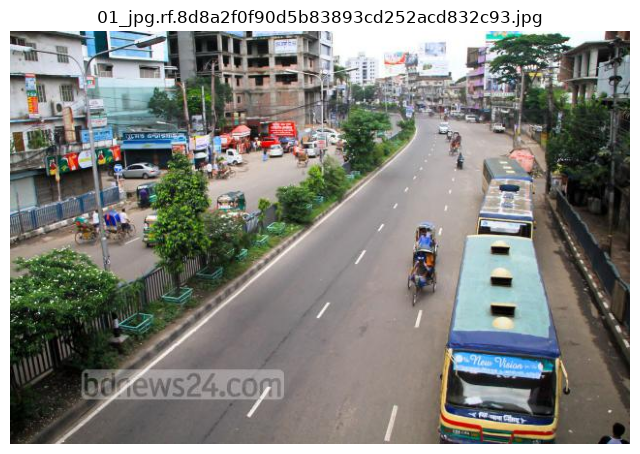

In [21]:
# Récupérer les images du dossier train
dossier_images = DATASET_DIR / "train" / "images"

images_train = sorted([
    f for f in dossier_images.iterdir()
    if f.is_file() and f.suffix.lower() in EXTENSIONS
])

# Afficher une image
if images_train:
    image_path = images_train[0]

    with Image.open(image_path) as image:
        plt.figure(figsize=(8, 6))
        plt.imshow(image.copy())
        plt.title(image_path.name)
        plt.axis("off")
        plt.show()
else:
    print("Aucune image trouvée.")